## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('./ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

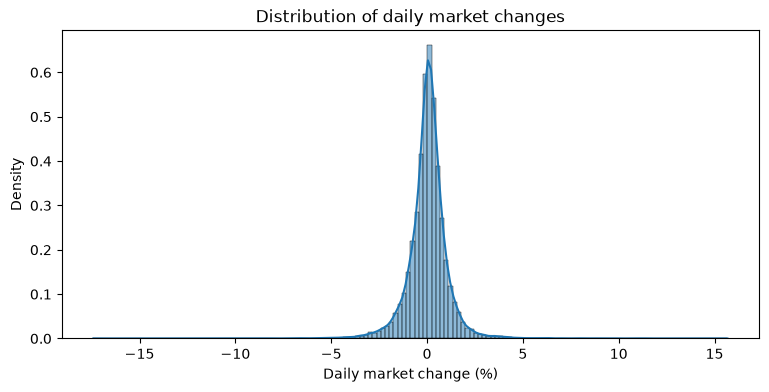

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

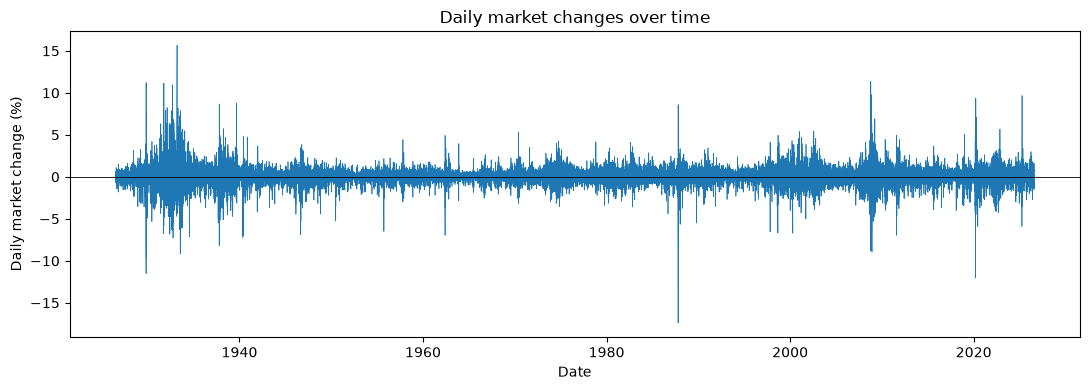

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
df['up']=np.where(df['market_return_pct']>=0, 'up', 'down')
df[['date', 'market_return_pct', 'up']].head(10)

,date,market_return_pct,up
0,1926-07-01,0.10,up
1,1926-07-02,0.46,up
2,1926-07-06,0.18,up
3,1926-07-07,0.10,up
4,1926-07-08,0.23,up
5,1926-07-09,-0.70,down
6,1926-07-10,0.62,up
7,1926-07-12,0.05,up
8,1926-07-13,0.49,up
9,1926-07-14,0.05,up


In [5]:
df['y_t'] = df['up']
df['y_tp1'] = df['up'].shift(-1) # Shift into the future
pd.crosstab(df['y_t'], df['y_tp1'])

y_tp1,down,up
y_t,,
down,5768,5967
up,5967,8593


### Joint crosstab

<Axes: xlabel='y_tp1', ylabel='y_t'>

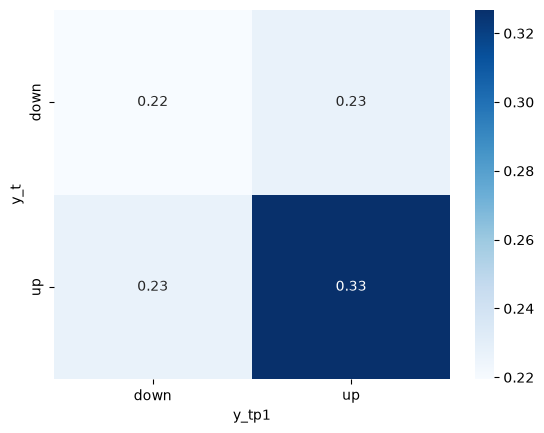

In [6]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

### Marginal crosstab

<Axes: xlabel='y_tp1', ylabel='y_t'>

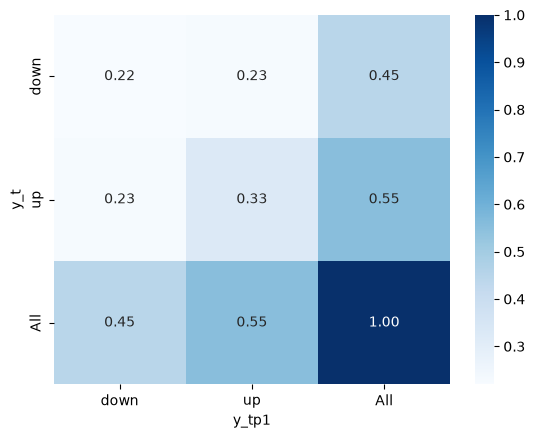

In [7]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = True, margins = True)
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

### Conditional PMF

In [8]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = 'index')
tab

y_tp1,down,up
y_t,,
down,0.491521,0.508479
up,0.409821,0.590179


<Axes: xlabel='y_tp1', ylabel='y_t'>

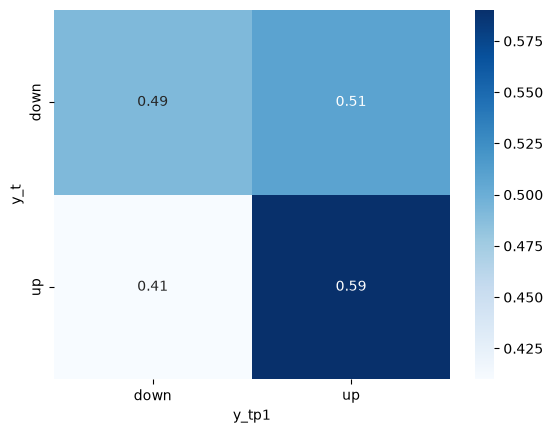

In [9]:
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

> Down-down transitions are the least common by a very slim margin occurring on 22% of day transitions. Down-up and Up-down transitions happen the same amount about 23% of the time during day transitions. Luckily, Up-up transitions are the most common happening at around 33% of all day transitions as seen from the joint crosstab.
>
> From the conditional PMF, we see a similar picture being painted. If a given day was a Down day, then there is 49% chance for another down day and a 51% of an up day. If a given day was an up day, then there are much better odds with 41% chance of the next day being a down day and a 59% chance of the next day being an up day. 

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [10]:
#Get the data again to get our last / first rows back
df = pd.read_parquet('./ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

In [11]:
bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels=['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['gains']=pd.cut(df['market_return_pct'], bins=bins, labels=labels, right=True,)

df[['date', 'market_return_pct', 'gains']].head()

,date,market_return_pct,gains
0,1926-07-01,0.10,Near zero
1,1926-07-02,0.46,Small gain
2,1926-07-06,0.18,Small gain
3,1926-07-07,0.10,Near zero
4,1926-07-08,0.23,Small gain


In [12]:
df['gains'].value_counts()

gains
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

### Joint PMF

<Axes: xlabel='y_tp1', ylabel='y_t'>

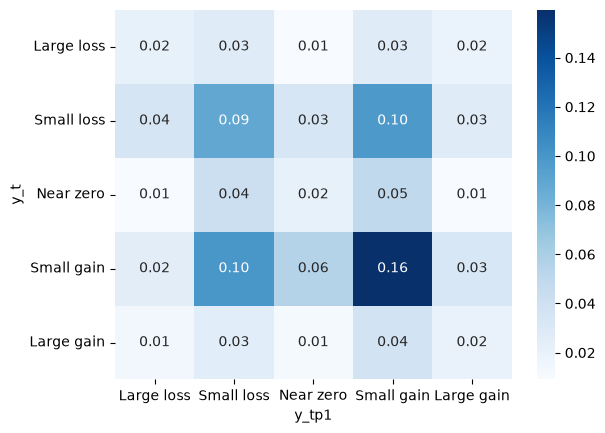

In [13]:
#slice data again with new variable
df['y_t'] = df['gains']
df['y_tp1'] = df['gains'].shift(-1) # Shift into the future
tab=pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')


### Marginal PMF

<Axes: xlabel='y_tp1', ylabel='y_t'>

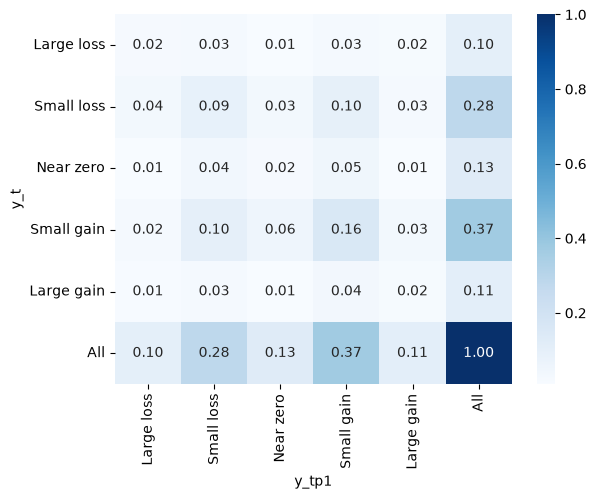

In [14]:
tab=pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=True)
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

> From the join and marginal PMF, the main hotspots are transitions from small-loss to small-gain and visa versa. They are the only transitions that happen more than 6% of the time. Small loss to small loss transition happens 9% of the time. Small loss to small gain and small gain to small loss occurs 10% of the time. Finally, small gain to small gain transition happens 16% of the time. 
>
> It is so interesting to see that even when we break it down further, the gain-to-loss and the loss-to-gain transition happens with the same likelihood. It is also good for investors that the most common outcome is the transition between 2 moderately good days in the market.
>
> The honorable mention for next most common transition is the small gain to near zero day with 6% of total transitions.

### Conditional PMF

<Axes: xlabel='y_tp1', ylabel='y_t'>

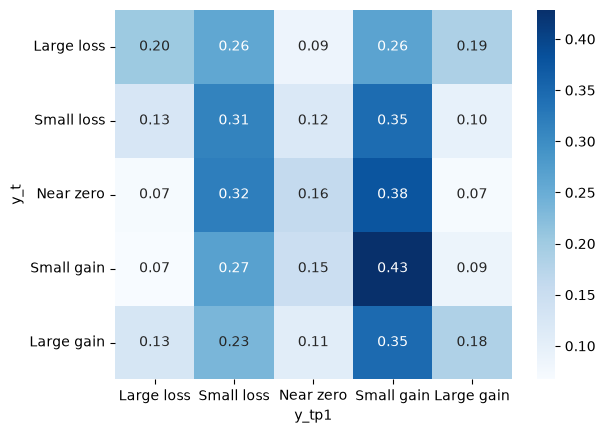

In [15]:
tab=pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

> Given that a day is a large loss, the next day is pretty likely to be anything except 0. Predicting the outcome is difficult since all future outcomes except 0 have similar probabilities. In other words, we don't know what tomorrow will bring, but it will be different that the price today.
>
> Near zero days and small gain days have very similar transition outcomes. There two most likely outcomes are small losses and small gains. There is a very small chance that the next day will be a large gain or a large loss with less than 10% for each transition. Around 30% of days will transition to small losses and around 40% will transition into small gains. Lastly, around 20% will be near zero. These days favor the traders the most. The market remains mostly steady with a slight tendency to go up. 
>
> Small loss days have similar transitions although have a higher chance to be more volatile. Its most common transitions are still to small loss or small gain. There is a 10% chance of small loss days having a large loss or large gain the next day, almost even likelihood of small gain or loss with 35 and 31% respectively and around 10% chance of staying the same.
>
> On days with large gains, the next day tends to have a good outcome with over half the next days having another gain (35% small and 18% large). Around a 25% to have a small loss, and around 10% to either do nothing or go down significantly. 
>
> No matter the outcome of a given day, the next day's mostly outcome is either a small loss or small gain. This can be seen through the gains value counts with around 75% of total days being a small loss or gain.


### Conditional expectation

In [16]:
#tomorrow's market
df['market_return_pct_tomorrow'] = df['market_return_pct'].shift(-1)
df.groupby('y_t', observed=False)['market_return_pct_tomorrow'].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


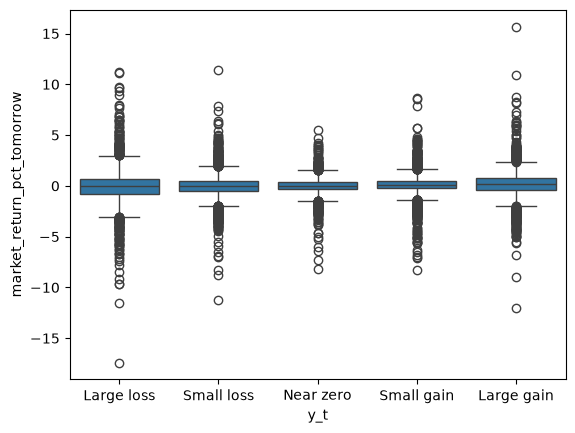

In [17]:
sns.boxplot(data=df, x="y_t", y="market_return_pct_tomorrow")
plt.show()

> Wow, the boxpolot is a lot less useful than I thought it would be. Let's see if we can get a useful plot by turning off outliers.

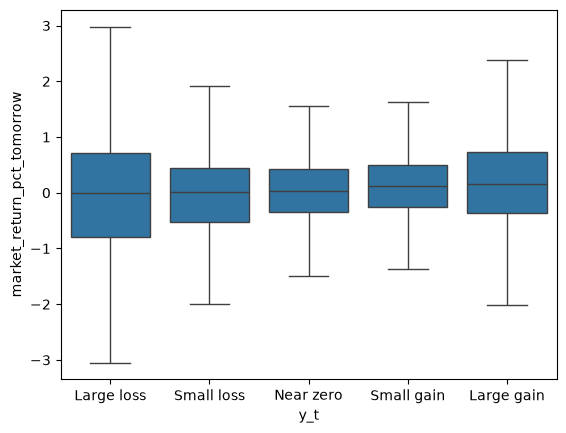

In [18]:
sns.boxplot(data=df, x="y_t", y="market_return_pct_tomorrow", showfliers=False)
plt.show()

> On large gain or large loss days, there is a high standard deviation over 1. Small loss days also have a sd>1 but less than the two large change days. Again, near zero and small gain have similar features with standard deviation at 0.8. Thus, the most volatile days are very good days and any bad days.
>
> After a bad day, the expected value for the next day is again bad! This is the first time we've seen this pattern. We saw that the most common after a bad day was a small gain, but we can see that on large or small loss days, the next day is expected to go down by around another 0.04 percent
>
> Luckily, on near 0 days and good days, the expected value of the next day is positive with near 0 days expecting an increase of 0.01% and good days expecting an increase of over 0.1% (wow, so great, right?). Even though these expected increases aer so small, it is nice to see that after a zero or good day, that you are expected to make more money tomorrow.
>
> The max changes for large loss days were 17% down or 11% up. For small losses the largest changes were down 11% or up 11%. For near zero days, they are down 8% and up 5%. Small gain days have a future range of down 8% and up 8%. Lastly, large gain days have a range of down 12% to up 15%. Seeing just how the max and min of each next day change highlights our conclusions with standard deviation and means.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [19]:
# bullet 1
# assigning values to the 21 bins

df['y_t'] = pd.qcut(df['market_return_pct'], q=21, labels=False) # looked up how to use qcut and plugged in the correct parameters
df['y_tp1'] = df['y_t'].shift(-1)

# looking at the values in each bin
df['y_t'].value_counts().sort_index()
# these look pretty uniformly distributed which makes sense because we used quantiles to help avoid the large class imbalances like before

y_t
0     1255
1     1253
2     1286
3     1280
4     1230
5     1226
6     1371
7     1206
8     1198
9     1331
10    1210
11    1223
12    1294
13    1223
14    1310
15    1193
16    1211
17    1283
18    1225
19    1250
20    1238
Name: count, dtype: int64

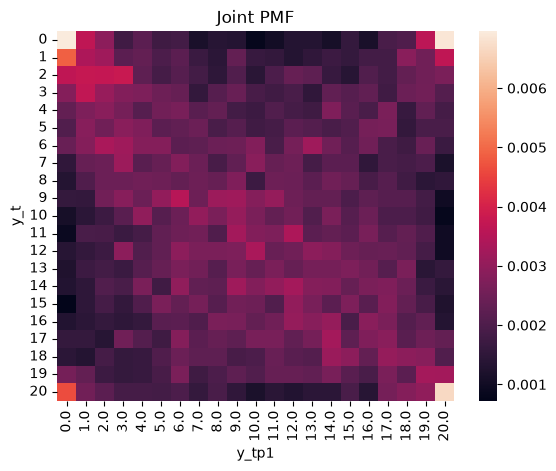

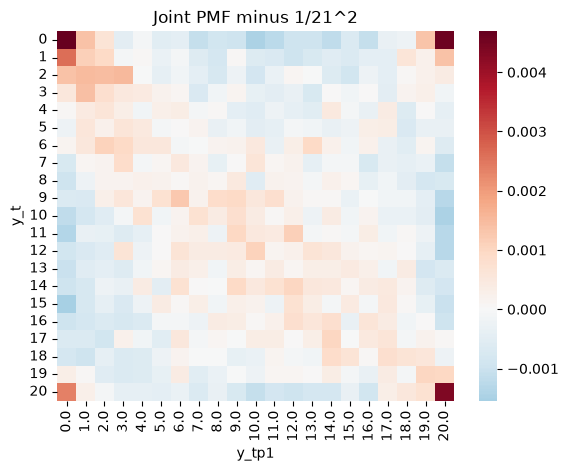

In [20]:
# bullet 2
# computing the joint PMF and plotting its heat map
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
sns.heatmap(tab).set(title='Joint PMF')
plt.show()

# now subtracting 1/21**2 to look at the differences
sns.heatmap(tab - 1/21**2, cmap='RdBu_r', center=0).set(title='Joint PMF minus 1/21^2')
plt.show()

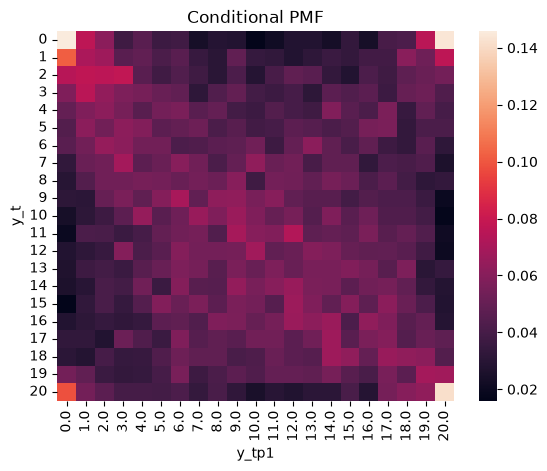

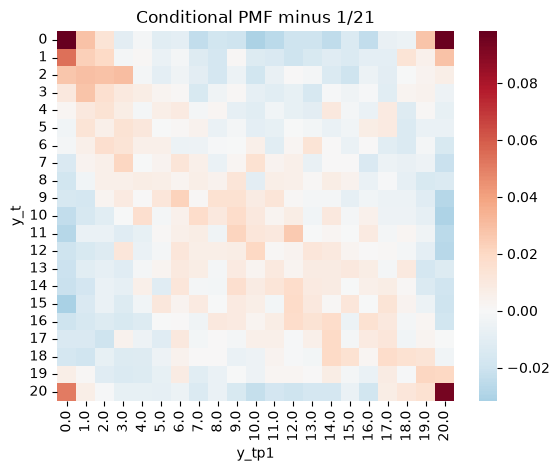

In [21]:
# bullet 3
# computing the conditional PMF and its heat map

# Adapted from review_conditioning.ipynb, cells bd7f55c7 and daa9efd9
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
sns.heatmap(tab).set(title='Conditional PMF')
plt.show()

# now subtracting 1/21
sns.heatmap(tab - 1/21, cmap='RdBu_r', center=0).set(title='Conditional PMF minus 1/21')
plt.show()

<Axes: title={'center': 'Next-day min, mean, max by bin'}, xlabel='y_t'>

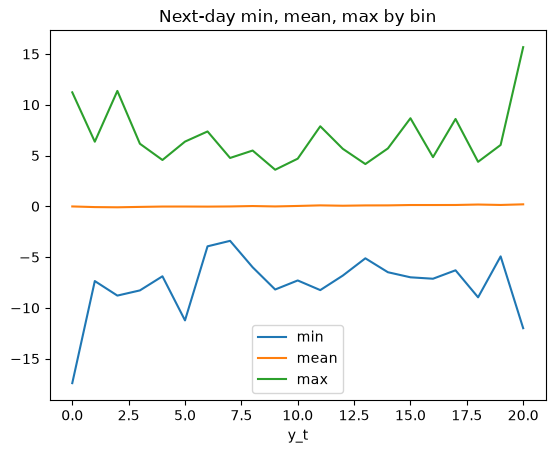

In [22]:
# bullet 4
# computing the next days min/mean/max and plotting

df['ret_tp1'] = df['market_return_pct'].shift(-1) # getting returns for the next day
# grouping by the returns of the next day and computing the stata
# using .plot to plot this directly (found online)
df.groupby('y_t')['ret_tp1'].agg(['min', 'mean', 'max']).plot(title='Next-day min, mean, max by bin')

<Axes: title={'center': 'Next-day std by bin'}, xlabel='y_t'>

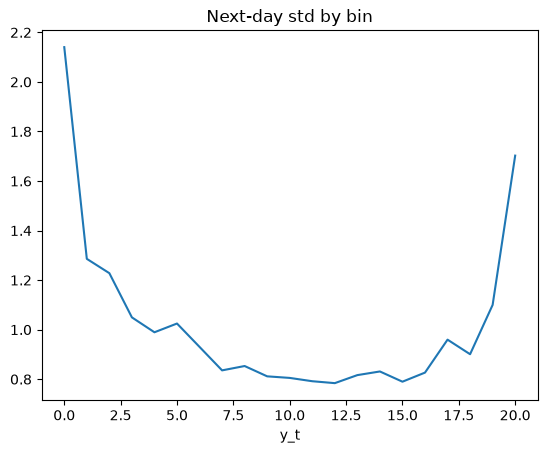

In [23]:
# bullet 5
# plotting the std for the next day by using .std() to get the std of returns
df.groupby('y_t')['ret_tp1'].std().plot(title='Next-day std by bin')

#### Do you see any obvious patterns (in regards to the joint PMF)? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.

> The first joint PMF heatmap looks pretty uninformative because all of the values hover around the same values so they get a deep red color. That said, we can see slightly lighter hues on the diagonals and at the corners of the graph. The corners having larger values means that the extremes are more likely to connect to other extremes which we know in the case from before. After subtracting 1/21^2 this pattern becomes a little more clear because now values hover around 0 so the change between positive and negative values is easy to see. We again see the diagonals having slightly larger values with the largest being in the corners. This confirms that extreme days are followed by extreme days much more often than uniform/random. The positive values along the diagonals indicate that days tend to be followed by days of a similar size, which again matches what we found before. The largest deviations from the uniform values occur at these corners/values since we know that the probability of having the next day was similar to the current day has a higher probability than randomly picking a day (so this heat map can help us beat random guess/uniform values).


#### Do you see any obvious patterns (in regards to the conditional PMF)? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.

> The heatmap of the conditional PMF before and after subtracting 1/21 show the same patterns captured by the joint PMF. After subtracting 1/21 the four corners stand out the most with positive values and the diagonals capture the next highest values. This leads us to the same conclusion: given that today is really bad (good), the chance that tomorrow is also in really bad (good) is much larger than all of other chances. In those same extreme cases, the values of going to another extreme case are high while the values for the less extreme bins around 2-18 are less common and have values below the uniform value. Furthermore, calmer days are followed by calm days and volatile days are followed by volatile days, as we can see from the larger values on the diagonal capturing the percentages from one bin to itself the next day. That said, since there are many bins and all the values are pretty low, it is still very hard to predict the exact bin of the following day knowing what today is, but we have agood chance at predicting a range of bins and the volatility of that bin.


#### Do you see any obvious patterns (in regards to the next day's min/mean/max)? Explain. 

> In this plot we have 3 different lines to capture the min, mean, and max. The most obvious result of this is that the mean line lies pretty much flat at 0 for all of the bins. This tells us that no matter what bin we are in today, the expected value/mean return for the next day is 0. This means that taking the conditional expected value for the next days return based on todays return shouldn't beat the market alone. Another pattern that emerges is the general symmetry between the min and max line, where they move in almost opposite directions. This captures the trend that expected returns for the next day are pretty much symmetrical and centered around 0, but this spread is dependent on how extreme the bin is. The min/max lines appear to get more extreme the further away they get from the middle, even more evidence that calmer days lead to less volatile returns the next day and more extreme days lead to more volatile returns the next day. 


#### Do you see any obvious patterns (in regard to the next day's standard deviation)? Explain.

> This standard deviation plot is clearly U-shaped, which matches our conclusions from before. It is highest at bins 0-2 and bins 19-20. Bin 0 has a large std of about 2.2 which then drops to around 0.8 at bin 11, before rising to around 1.6 at bin 20. The sharp dip, steady down/up, and sharp rise is the U-shaped pattern that is consistent with our findings that more volatile days are followed by more volatile days. This high correlation between volatility means we should have decent information about tomorrows volatility given what is today (although this volatility does not capture positive/negative returns). Lastly, the left side is higher than the right so big losses are followed by more uncertainty than big gains. 


#### How easy is it to predict the market?

> Putting all of this together, the market is not easy to predict. The conditional expected returns are very close to zero, and they are tiny compared to the large standard deviations (around 0.8% to 2.1%). We have also seen that we are much better at predicting the volatilty of the next day given todays volatility, but we are not sure which direction this volatility will push the sign of the returns towards. The strongest cell in the conditional PMF, from bin 0 to bin 0, only happens about 1/8 of the time, but from the extreme bins the next day is almost equally likely to land in either extreme so we could do really good or really bad. All together, the market's direction is close to unpredictable from today's bin alone while the size of the next move (volatility) is somewhat predictable, meaning that we have very little useful information to beat the market.